# Do HMM regimes capture anything other than variance? (pre-registered, final)

Earlier tests asked the HMM to forecast volatility, where VIX/GARCH/EWMA target the quantity directly. An HMM only has a reason to exist if regimes change something *else*: **correlations, drift or the joint distribution**. This notebook gives it that chance on an asset set where correlations genuinely move, and it is run **once**; the answer is final. No variants will be tried afterwards.

## Design (fixed in advance)

* **Primary market: US stock / bond / gold** = SPY, TLT, GLD (total-return ETFs, 2004-11 -> 2026). Stock-bond correlation was negative for ~20 years and flipped positive in 2022, so this is the fairest available testbed.
* **Replication (cannot rescue a primary failure): India** = Nifty 50, USDINR, GoldBees (INR), 2009 -> 2026.
* **Model:** HMM fit **directly on the joint daily log-return vector** (not on vol features), K = 3, **full-covariance** Gaussian emissions (so regimes may differ in correlation, drift and variance), best of 10 restarts, 3y warm-up, refit every 6 months, **filtered** probabilities only. States ordered calm -> stress by total variance.
* **Benchmarks (all causal, same OOS days):** (i) **EWMA covariance** (RiskMetrics, lambda 0.94) -- correlations may drift smoothly, no regimes; (ii) EWMA vols + **constant correlation** (diagnostic). Means for all models = train-window mean.

## Kill rule

The HMM is **dropped** as something-beyond-a-vol-tracker unless **both** hold on the primary market:

1. **(Step 1, necessary condition)** The correlations of *vol-standardised* returns (`r / EWMA one-step vol`, removing the mechanical rise of sample correlation in volatile periods) **differ across regimes more than chance**: max-over-pairs range of within-regime correlation, circular-shift permutation test (2,000 shifts, preserves label persistence), **p < 0.05**. Regime label at day *t* = the **previous day's filtered argmax**, so the label is known before the return it is conditioning (no look-ahead, no mechanical selection on the return itself).
2. **(Step 2)** The HMM's mean one-step-ahead **joint predictive log-score beats EWMA-cov** and the Diebold-Mariano test (two-sided, HLN-corrected) gives **p < 0.10**.

Outcomes: fail either -> **dropped, final**. Pass both on US but fail either on India -> **not robust, not adopted**. Pass both on both -> a *separate* pre-registered allocation test (not run here).

The log-score decomposition (joint = marginals + dependence), per-pair permutation p-values, correlation tables and the constant-correlation comparison are **descriptive** and cannot rescue a failed rule.


drop_bad_prints: removed 2 dates: ['2019-12-19', '2019-12-20']
US: 2004-11-18 -> 2026-10-19 (5513 rows)
India: 2009-01-02 -> 2026-10-16 (4353 rows)

Full-sample correlations (US):


,stocks,bonds,gold
stocks,1.00,-0.30,0.07
bonds,-0.30,1.00,0.16
gold,0.07,0.16,1.00


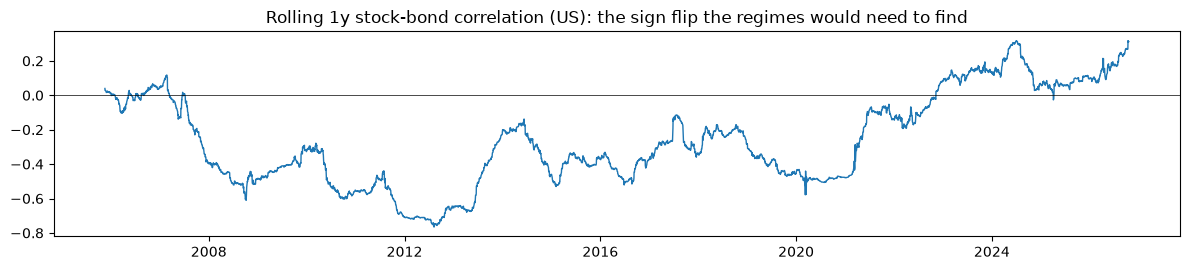

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import regime_filter as rf, corr_regime_eval as cr

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
US = {"stocks": "SPY", "bonds": "TLT", "gold": "GLD"}
IN = {"nifty": "^NSEI", "usdinr": "USDINR=X", "gold_inr": "GOLDBEES.NS"}

us_px = cr.load_set(US, "us_stock_bond_gold.csv")
in_px = cr.load_set(IN, "india_nifty_usdinr_gold.csv", price_cols=["nifty", "gold_inr"])
for n, p in [("US", us_px), ("India", in_px)]:
    print(f"{n}: {p.index.min().date()} -> {p.index.max().date()} ({len(p)} rows)")
r_us, r_in = us_px.pct_change().dropna(), in_px.pct_change().dropna()
print("\nFull-sample correlations (US):"); display(r_us.corr().round(2))
roll = r_us["stocks"].rolling(252).corr(r_us["bonds"])
fig, ax = plt.subplots(figsize=(12, 2.8)); ax.plot(roll, lw=1); ax.axhline(0, color="k", lw=0.5)
ax.set_title("Rolling 1y stock-bond correlation (US): the sign flip the regimes would need to find"); plt.tight_layout(); plt.show()

## 1. Primary: US stock / bond / gold

OOS 2007-11-21 -> 2026-10-19  (4756 days, 38 refits)
Share of OOS days by (lagged) filtered regime: {0: 0.48, 1: 0.409, 2: 0.111}


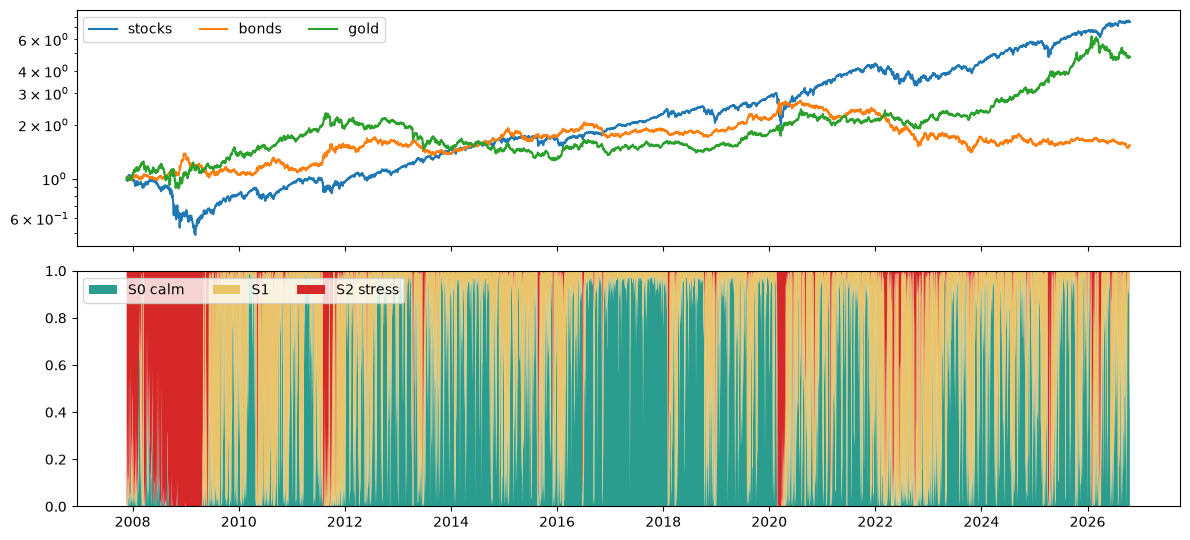

In [2]:
cfg = cr.CorrWFConfig(n_states=3, warmup_days=756, refit_days=126, n_init=10, seed=42)
B = cr.run_models(r_us, cfg)
oos = B["scores"].index
print(f"OOS {oos.min().date()} -> {oos.max().date()}  ({len(oos)} days, {B['fold'].nunique()} refits)")
print("Share of OOS days by (lagged) filtered regime:", B["labels"].value_counts(normalize=True).sort_index().round(3).to_dict())

fig, ax = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
ax[0].plot((1 + r_us.reindex(oos)).cumprod()); ax[0].set_yscale("log"); ax[0].legend(r_us.columns, ncol=3)
ax[1].stackplot(oos, B["filtered"].T.values, colors=["#2a9d8f", "#e9c46a", "#d62828"], labels=["S0 calm", "S1", "S2 stress"]); ax[1].set_ylim(0, 1); ax[1].legend(ncol=3, loc="upper left")
plt.tight_layout(); plt.show()

### Step 1: do correlations differ across regimes?

In [3]:
def step1(B, cols, n_states=3):
    Z = cr.standardised_residuals(B, B["scores"].index)
    lab = B["labels"].to_numpy()
    tabs = cr.regime_corr_table(Z, lab, n_states)
    iu = np.triu_indices(len(cols), 1)
    names = [f"{cols[i]}~{cols[j]}" for i, j in zip(*iu)]
    tbl = pd.DataFrame({f"S{k}": [t[iu][j] for j in range(len(names))] for k, t in tabs.items() if t is not None}, index=names)
    tbl["days"] = None
    obs, per_pair, p_max, p_pair = cr.permutation_pvalue(Z, lab, n_states, n_perm=2000, seed=0)
    out = tbl.drop(columns="days").assign(range=per_pair, perm_p=p_pair)
    print("Within-regime correlation of vol-standardised returns (regime = previous day's filtered state):")
    display(out.round(3))
    print("Days per regime:", pd.Series(lab).value_counts().sort_index().to_dict())
    print(f"Max-range statistic = {obs:.3f}; permutation p (family-wise, max over pairs) = {p_max:.4f}")
    return p_max

p1_us = step1(B, list(r_us.columns))

Within-regime correlation of vol-standardised returns (regime = previous day's filtered state):


,S0,S1,S2,range,perm_p
stocks~bonds,-0.207,-0.285,-0.415,0.208,0.354
stocks~gold,0.045,0.074,-0.068,0.142,0.404
bonds~gold,0.277,0.175,0.163,0.114,0.535


Days per regime: {0: 2285, 1: 1943, 2: 528}
Max-range statistic = 0.208; permutation p (family-wise, max over pairs) = 0.4888


### Step 2: does the HMM predict the joint return distribution better than EWMA covariance?

In [4]:
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
cmp_us = cr.score_comparison(B)
print("Mean one-step predictive log-score (higher = better), HMM vs benchmarks:"); display(cmp_us)
print("\nDecomposition per model, mean per day (joint = marginals + dependence):"); display(cr.decomposition(B))
print("Mean log-score of all models:", B["scores"].mean().round(4).to_dict())

Mean one-step predictive log-score (higher = better), HMM vs benchmarks:


,mean_logscore_HMM,mean_logscore_bench,HMM_minus_bench (logscore),DM_stat,DM_p
benchmark,,,,,
EWMA-cov,-4.1911,-4.0549,-0.1362,4.5670,0.0000
EWMA-vol+constR,-4.1911,-4.0913,-0.0998,3.7893,0.0002



Decomposition per model, mean per day (joint = marginals + dependence):


,joint,marginals,dependence
HMM,-4.1911,-4.2607,0.0696
EWMA-cov,-4.0549,-4.1446,0.0897
EWMA-vol+constR,-4.0913,-4.1446,0.0533


Mean log-score of all models: {'HMM': -4.1911, 'EWMA-cov': -4.0549, 'EWMA-vol+constR': -4.0913}


In [5]:
def verdict(p1, cmp, label):
    a = p1 < 0.05
    row = cmp.loc["EWMA-cov"]
    b = (row["HMM_minus_bench (logscore)"] > 0) and (row["DM_p"] < 0.10)
    print(f"[{label}] Step 1: permutation p = {p1:.4f} -> {'PASS' if a else 'FAIL'}")
    print(f"[{label}] Step 2: dLogScore(HMM-EWMAcov) = {row['HMM_minus_bench (logscore)']:+.4f}, DM p = {row['DM_p']:.3f} -> {'PASS' if b else 'FAIL'}")
    return a, b

a_us, b_us = verdict(p1_us, cmp_us, "US")
print("\nUS VERDICT:", "both pass -> check India replication" if (a_us and b_us) else "KILL RULE TRIGGERED -> HMM dropped; no allocation test")

[US] Step 1: permutation p = 0.4888 -> FAIL
[US] Step 2: dLogScore(HMM-EWMAcov) = -0.1362, DM p = 0.000 -> FAIL

US VERDICT: KILL RULE TRIGGERED -> HMM dropped; no allocation test


## 2. Replication: India (Nifty / USDINR / GoldBees)
Same code and settings. Cannot rescue a US failure.

In [6]:
B2 = cr.run_models(r_in, cfg)
oos2 = B2["scores"].index
print(f"OOS {oos2.min().date()} -> {oos2.max().date()}  ({len(oos2)} days)")
p1_in = step1(B2, list(r_in.columns))
cmp_in = cr.score_comparison(B2)
display(cmp_in); print("\nDecomposition:"); display(cr.decomposition(B2))
a_in, b_in = verdict(p1_in, cmp_in, "India")

OOS 2012-02-08 -> 2026-10-16  (3596 days)


Within-regime correlation of vol-standardised returns (regime = previous day's filtered state):


,S0,S1,range,perm_p
nifty~usdinr,-0.1380,-0.1360,0.0020,0.9730
nifty~gold_inr,-0.0630,-0.0950,0.0320,0.5960
usdinr~gold_inr,-0.0160,0.0930,0.1100,0.0460


Days per regime: {0: 2541, 1: 973, 2: 82}
Max-range statistic = 0.110; permutation p (family-wise, max over pairs) = 0.1124


,mean_logscore_HMM,mean_logscore_bench,HMM_minus_bench (logscore),DM_stat,DM_p
benchmark,,,,,
EWMA-cov,-3.0382,-3.0821,0.0438,-1.0971,0.2727
EWMA-vol+constR,-3.0382,-3.0407,0.0025,-0.0659,0.9474



Decomposition:


,joint,marginals,dependence
HMM,-3.0382,-3.0385,0.0002
EWMA-cov,-3.0821,-3.0452,-0.0369
EWMA-vol+constR,-3.0407,-3.0452,0.0044


[India] Step 1: permutation p = 0.1124 -> FAIL
[India] Step 2: dLogScore(HMM-EWMAcov) = +0.0438, DM p = 0.273 -> FAIL


In [7]:
print("=" * 72)
if not (a_us and b_us):
    final = "DROPPED: HMM fails the pre-registered rule on the primary (US) market. FINAL."
elif a_in and b_in:
    final = "SURVIVES both markets: a separate pre-registered allocation test is warranted."
else:
    final = "NOT ROBUST: passes on US but fails on India; not adopted."
print("FINAL VERDICT:", final)

FINAL VERDICT: DROPPED: HMM fails the pre-registered rule on the primary (US) market. FINAL.


## Conclusions (final)

**Verdict under the pre-registered rule: the HMM is dropped.** It fails both steps on the primary (US stock / bond / gold) market, and both steps on the India replication.

**US (2007-11 -> 2026-10, 4,756 OOS days, 38 refits):**
* **Step 1 FAIL.** Within-regime correlations of vol-standardised returns barely move across regimes: stock-bond -0.21 / -0.29 / -0.42, stock-gold +0.05 / +0.07 / -0.07, bond-gold +0.28 / +0.18 / +0.16. Max-range statistic 0.21, family-wise permutation p = 0.49. The regimes the HMM found are not correlation regimes.
* **Step 2 FAIL, and in the wrong direction.** Mean joint log-score: HMM -4.191 vs EWMA-cov -4.055 vs EWMA-vol + constant correlation -4.091. The HMM is *significantly worse* than both (DM p < 0.001). The decomposition shows it loses on the marginals (-4.261 vs -4.145: its three variance levels track volatility more coarsely than EWMA) **and** on dependence (+0.070 vs +0.090 for EWMA-cov).

**India replication (2012-02 -> 2026-10, 3,596 days):** Step 1 fails (p = 0.11; the one pair with an unadjusted p of 0.046, USDINR vs INR-gold, is partly mechanical, since gold priced in INR contains USDINR, and does not survive the family-wise correction). Step 2: the HMM's log-score is higher than EWMA-cov (+0.044) but not significantly (p = 0.27), and indistinguishable from the constant-correlation benchmark (p = 0.95). In this set smoothly time-varying correlation (EWMA-cov) is actually *worse* than a constant correlation (dependence -0.037 vs +0.004), i.e. these India correlations are close to stable. One regime has only 82 days.

**What this does and does not show.**
* It shows that a K=3 full-covariance Gaussian HMM fit on daily returns, with regimes ordered by variance, does not recover correlation regimes in US stock/bond/gold or India equity/FX/gold, and does not improve on EWMA covariance forecasts.
* It does **not** prove correlation regimes don't exist. The 2022 stock-bond sign flip is a slow, persistent shift that a variance-ordered 3-state model fit on 756+ days of mostly negative-correlation history may simply not isolate; a model that explicitly targets the correlation process (e.g. DCC with regime-switching intercept, or rolling-correlation features) is a different hypothesis and would need its own pre-registration.
* Daily returns with 35 free parameters per fit are noisy; the HMM's weaker marginals suggest estimation error is part of the story.

**Full project conclusion.** Leak-free HMM regimes (i) describe volatility, but forecast it no better than EWMA/GARCH/VIX; (ii) add no timing value over a trailing-vol rule on Nifty; (iii) add no allocation value over static or equal weights; (iv) on the S&P a stress probability has some incremental information about forward vol but does not improve forecast loss; and (v) do not identify correlation regimes on the two asset sets where one would most expect them. The right engineering choice is to use the simpler tools. As agreed, this answer is final and no variants will be run.
